# Projeto 1 – Modelação: Clustering
## Agrupar os bebés pelas condições clínicas (Grupo 5)

Este notebook implementa a parte de **clustering** dos capítulos 5 e 6 do relatório. Parte de `dataset_clustering.csv` (notebook 02) e segue a estrutura do demo da aula (`demo_clustering.ipynb`): escolher o número de clusters com o método do cotovelo e a *silhouette*, aplicar o K-means e descrever cada cluster.

Diferenças em relação ao demo:

| Demo da aula | Este notebook | Porquê |
|---|---|---|
| 2 variáveis na mesma escala (Income, Score) | Várias variáveis, normalizadas com `StandardScaler` | O K-means usa distâncias: sem normalizar, a variável com números maiores decide sozinha |
| Só *silhouette* e cotovelo | *Silhouette*, Davies-Bouldin, Calinski-Harabasz, tamanho mínimo, diferença no internamento e estabilidade (ARI em *bootstrap*) | São os critérios da Tabela 8 do relatório |
| Só K-means | K-means e *clustering* hierárquico (Ward) | Tabela 13 do relatório |
| Gráfico com as 2 variáveis | Gráfico nas 2 primeiras componentes principais (PCA) | Com mais de 2 variáveis não se pode desenhar diretamente |

| Secção do relatório | O que este notebook faz |
|---|---|
| 5.1 Selecionar técnicas | Algoritmos e escolha das variáveis |
| 5.2 Desenho de teste | Métricas internas, validação externa, estabilidade |
| 5.3 Construir modelos | K-means e Ward para k = 2 a 5 |
| 5.4 Avaliar modelos | Escolha de k, perfis dos clusters, comparação com todas as variáveis |
| 6.1 Avaliar resultados | Comparação com a Tabela 8 |

## 0. Configuração

In [1]:
# --- Bibliotecas ---
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib                                   # guardar o modelo final (Projeto 2)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# --- Pastas (mesma lógica dos notebooks 01 e 02) ---
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC_DIR = ROOT / "data" / "processed"                      # saída do notebook 02
MODEL_DIR = ROOT / "models"                                  # modelos finais para o BI
FIG_DIR = ROOT / "reports" / "figures" / "modeling_clustering"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42                                                    # mesma semente em todo o lado (reprodutibilidade)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.stats import kruskal, spearmanr

K_CANDIDATOS = range(2, 6)      # Tabela 8: comparar k = 2 a 5 (com 47 bebés, k > 5 dá grupos muito pequenos)
N_BOOTSTRAP = 100
CORES = ["#1f3864", "tab:orange", "tab:green", "tab:red", "tab:purple"]

## Carregar os dados

Uma linha por bebé, com o internamento completo. `los_validacao` e `cens_direita` **não** entram no agrupamento: servem só para validar os clusters depois.

In [2]:
d = pd.read_csv(PROC_DIR / "dataset_clustering.csv")
los = d["los_validacao"]
FRAC = [c for c in d.columns if c.startswith("frac_dias_pat_")]
SINAIS = [c for c in d.columns if c not in ["episodio", "los_validacao", "cens_direita", "n_patologias_distintas"] + FRAC]
print(f"{len(d)} bebés | {len(SINAIS)} variáveis de sinais vitais | {len(FRAC)} frações de dias com patologia")

47 bebés | 19 variáveis de sinais vitais | 5 frações de dias com patologia


## 5.1 Selecionar técnicas de modelação

### Que variáveis usar?

O enunciado pede o agrupamento dos bebés **em termos de condições clínicas**. Por isso, o agrupamento principal usa as patologias. Os sinais vitais ficam para descrever os clusters e para uma comparação no fim (secção 5.4).

O `dataset_clustering.csv` tem as patologias como **fração dos dias de internamento** (`frac_dias_pat_*`). Essa fração tem o tempo de internamento no denominador, e a validação externa da Tabela 8 é precisamente a diferença no internamento entre clusters. Usar as frações tornaria a validação parcialmente circular: os clusters difeririam no internamento porque a variável foi construída com ele.

Por isso usamos a **presença** de cada grupo de patologias em algum dia do internamento (`tem_pat_* = 1` se a fração for maior do que 0). O internamento não entra no cálculo desta variável, e ela é mais fácil de interpretar: "bebés com DMH e icterícia", em vez de "bebés com 40% dos dias com DMH".

A tabela abaixo mostra que a presença também está associada ao internamento (por exemplo, a icterícia). Essa associação é real, não um artefacto: os bebés com certas patologias ficam mais tempo internados. É precisamente o que a validação externa quer detetar. Também deixamos de fora `n_patologias_distintas`, a variável mais ligada ao internamento (ρ = 0,63), porque já está implícita nas cinco variáveis de presença.

In [3]:
TEM = [c.replace("frac_dias_pat_", "tem_pat_") for c in FRAC]
d[TEM] = (d[FRAC] > 0).astype(int).to_numpy()

# Correlação de Spearman de cada variável com o internamento: as frações e a contagem estão mais ligadas a ele
corr = pd.DataFrame({"variavel": FRAC + TEM + ["n_patologias_distintas"],
                     "rho_com_internamento": [spearmanr(d[c], los)[0] for c in FRAC + TEM + ["n_patologias_distintas"]]}).round(2)
display(corr)
print("Bebés com cada grupo de patologias:", d[TEM].sum().to_dict())
print("Bebés sem nenhuma patologia:", (d[TEM].sum(axis=1) == 0).sum())

,variavel,rho_com_internamento
0,frac_dias_pat_dmh,0.11
1,frac_dias_pat_ictericia,0.43
2,frac_dias_pat_anemia,0.36
3,frac_dias_pat_cmv,0.12
4,frac_dias_pat_outra,0.38
5,tem_pat_dmh,0.21
6,tem_pat_ictericia,0.51
7,tem_pat_anemia,0.39
8,tem_pat_cmv,0.11
9,tem_pat_outra,0.38


Bebés com cada grupo de patologias: {'tem_pat_dmh': 28, 'tem_pat_ictericia': 21, 'tem_pat_anemia': 7, 'tem_pat_cmv': 7, 'tem_pat_outra': 9}
Bebés sem nenhuma patologia: 8


### Algoritmos

- **K-means** (do demo): procura k centros e atribui cada bebé ao mais próximo.
- **Hierárquico aglomerativo (Ward)**: junta, passo a passo, os grupos cuja fusão menos aumenta a variância. Dá um dendrograma e não depende de uma inicialização aleatória.

A mistura de gaussianas, prevista na Tabela 13, foi posta de parte: as variáveis de agrupamento são 0/1, e uma gaussiana não é um modelo razoável para dados binários.

As variáveis são normalizadas para o K-means e o Ward darem o mesmo peso a cada patologia, independentemente de ser rara ou frequente.

In [4]:
X = d[TEM]
Z = StandardScaler().fit_transform(X)

## 5.2 Gerar o desenho de teste

Não há uma etiqueta verdadeira, por isso avaliamos os clusters de três formas (Tabela 8):

1. **Métricas internas**: *silhouette* (−1 a 1, maior é melhor), Davies-Bouldin (maior que 0, menor é melhor) e Calinski-Harabasz (maior é melhor).
2. **Validação externa**: o internamento difere entre clusters? Teste de Kruskal-Wallis, que não assume distribuição normal.
3. **Estabilidade**: refazemos o agrupamento em 100 amostras *bootstrap* (sorteio dos bebés com reposição) e medimos, com o ARI (*Adjusted Rand Index*), se os bebés sorteados ficam agrupados da mesma forma. ARI = 1 significa grupos iguais; 0 significa concordância ao acaso.

Também exigimos que cada cluster tenha pelo menos 3 bebés.

In [5]:
ALGORITMOS = {
    "K-means": lambda k: KMeans(n_clusters=k, n_init=20, random_state=SEED),
    "Ward": lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"),
}

def ari_bootstrap(fabrica, Z, rotulos, n=N_BOOTSTRAP):
    # Compara os grupos originais com os obtidos numa amostra bootstrap, só nos bebés sorteados
    rng = np.random.default_rng(SEED)
    aris = []
    for _ in range(n):
        idx = np.unique(rng.choice(len(Z), len(Z), replace=True))
        aris.append(adjusted_rand_score(rotulos[idx], fabrica().fit_predict(Z[idx])))
    return np.mean(aris)

def avaliar(Z, nome, fabrica, k):
    rot = fabrica(k).fit_predict(Z)
    return rot, {
        "algoritmo": nome, "k": k,
        "silhouette": silhouette_score(Z, rot), "davies_bouldin": davies_bouldin_score(Z, rot),
        "calinski_harabasz": calinski_harabasz_score(Z, rot),
        "menor_cluster": np.bincount(rot).min(),
        "kruskal_p": kruskal(*[los[rot == c] for c in np.unique(rot)]).pvalue,
        "ARI_bootstrap": ari_bootstrap(lambda: fabrica(k), Z, rot)}

## 5.3 Construir os modelos

### Método do cotovelo e *silhouette* (como no demo)

Primeiro olhamos para as duas curvas do demo, com k de 2 a 8, só com o K-means.

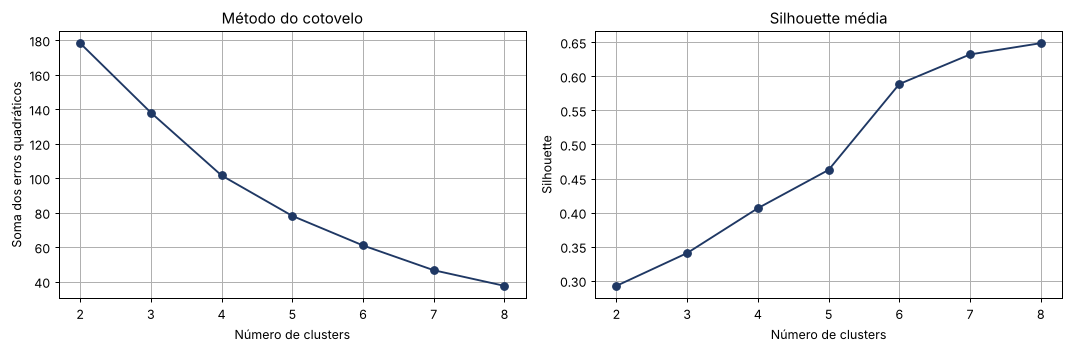

In [6]:
ks = range(2, 9)
sse, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    sse.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, sse, marker="o", color="#1f3864")
axes[0].set(xlabel="Número de clusters", ylabel="Soma dos erros quadráticos", title="Método do cotovelo")
axes[1].plot(ks, sil, marker="o", color="#1f3864")
axes[1].set(xlabel="Número de clusters", ylabel="Silhouette", title="Silhouette média")
for ax in axes:
    ax.set_xticks(list(ks))
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "figura_cotovelo_silhouette.png", dpi=200, bbox_inches="tight")
plt.show()

### Comparação de k = 2 a 5 com todos os critérios (Tabela 31 do relatório)

A coluna `cumpre_tudo` indica se a solução cumpre os quatro limiares da Tabela 8: *silhouette* > 0,25, menor cluster ≥ 3 bebés, Kruskal-Wallis p < 0,05 e ARI ≥ 0,6.

In [7]:
linhas, rotulos = [], {}
for nome, fabrica in ALGORITMOS.items():
    for k in K_CANDIDATOS:
        rotulos[(nome, k)], m = avaliar(Z, nome, fabrica, k)
        linhas.append(m)
comparacao = pd.DataFrame(linhas)
comparacao["cumpre_tudo"] = ((comparacao["silhouette"] > 0.25) & (comparacao["menor_cluster"] >= 3) &
                             (comparacao["kruskal_p"] < 0.05) & (comparacao["ARI_bootstrap"] >= 0.6)).map({True: "✔", False: ""})
display(comparacao.round(3))
comparacao.round(3).to_csv(FIG_DIR / "tabela_clustering_k.csv", index=False)

,algoritmo,k,silhouette,davies_bouldin,calinski_harabasz,menor_cluster,kruskal_p,ARI_bootstrap,cumpre_tudo
0,K-means,2,0.292,1.594,14.313,19,0.149,0.324,
1,K-means,3,0.341,1.324,15.456,9,0.021,0.407,
2,K-means,4,0.406,1.062,18.832,7,0.000,0.487,
3,K-means,5,0.463,0.946,21.085,6,0.015,0.734,✔
4,Ward,2,0.353,1.281,12.775,7,0.009,0.398,
5,Ward,3,0.395,1.177,15.893,7,0.016,0.630,✔
6,Ward,4,0.390,1.080,17.833,7,0.011,0.575,
7,Ward,5,0.459,0.916,20.791,5,0.018,0.733,✔


## 5.4 Avaliar os modelos

### Solução escolhida

Escolhemos o **K-means com k = 5**: tem a maior *silhouette* (0,46), o menor Davies-Bouldin, o maior Calinski-Harabasz e a maior estabilidade (ARI 0,73), e cumpre os quatro critérios. O Ward com k = 5 também os cumpre e dá praticamente os mesmos grupos (ARI 0,97 entre os dois), o que reforça a escolha. O Ward com k = 3 também passa, mas os grupos são menos específicos.

In [8]:
ALG_FINAL, K_FINAL = "K-means", 5
d["cluster"] = rotulos[(ALG_FINAL, K_FINAL)]
print("Bebés por cluster:", d["cluster"].value_counts().sort_index().to_dict())
print(f"Concordância K-means vs. Ward (k={K_FINAL}): ARI = {adjusted_rand_score(d['cluster'], rotulos[('Ward', K_FINAL)]):.2f}")

Bebés por cluster: {0: 17, 1: 6, 2: 7, 3: 6, 4: 11}
Concordância K-means vs. Ward (k=5): ARI = 0.97


### Perfil de cada cluster

Para cada cluster: número de bebés, % de bebés com cada grupo de patologias, internamento e as médias dos sinais vitais. Os sinais vitais **não** foram usados para formar os grupos, por isso as diferenças que aparecem aqui são uma validação adicional.

In [9]:
perfil = d.groupby("cluster").agg(
    bebes=("episodio", "size"),
    **{f"%{c.replace('tem_pat_', '')}": (c, lambda s: round(s.mean() * 100)) for c in TEM},
    n_patologias_media=("n_patologias_distintas", "mean"),
    internamento_mediana=("los_validacao", "median"),
    internamento_media=("los_validacao", "mean"),
    sat_o2_media=("sat_o2_media", "mean"),
    puls_rate_media=("puls_rate_media", "mean"),
    perfusion_media=("perfusion_media", "mean"),
    pct_horas_sat_lt90=("pct_horas_sat_lt90", "mean"),
).round(1)
display(perfil)
perfil.to_csv(FIG_DIR / "tabela_perfis_clusters.csv")

# Os sinais vitais diferem entre clusters? (Kruskal-Wallis, só como descrição)
kw_sinais = pd.Series({s: kruskal(*[d.loc[d.cluster == c, s] for c in range(K_FINAL)]).pvalue
                       for s in ["sat_o2_media", "puls_rate_media", "perfusion_media", "pct_horas_sat_lt90"]}).round(3)
print("p-valor de Kruskal-Wallis dos sinais vitais entre clusters:", kw_sinais.to_dict())

,bebes,%dmh,%ictericia,%anemia,%cmv,%outra,n_patologias_media,internamento_mediana,internamento_media,sat_o2_media,puls_rate_media,perfusion_media,pct_horas_sat_lt90
cluster,,,,,,,,,,,,,
0,17,100,53,0,0,0,1.5,10.0,10.4,96.4,142.4,1.2,0.4
1,6,33,33,0,100,0,1.7,9.0,12.2,96.7,145.0,1.1,0.2
2,7,57,57,100,0,43,3.0,23.0,23.3,96.2,148.2,1.2,1.9
3,6,83,50,0,17,100,2.7,15.0,17.3,96.1,141.9,1.2,0.5
4,11,0,27,0,0,0,0.3,6.0,6.6,96.0,135.0,1.3,0.4


p-valor de Kruskal-Wallis dos sinais vitais entre clusters: {'sat_o2_media': 0.854, 'puls_rate_media': 0.129, 'perfusion_media': 0.798, 'pct_horas_sat_lt90': 0.185}


**Os cinco perfis** (os números referem-se à tabela acima):

| Cluster | Bebés | Perfil clínico | Internamento (mediana) | Leitura para o negócio |
|---|---|---|---|---|
| C4 | 11 | Sem patologia ou só icterícia (0,3 patologias em média) | 6 dias | Internamentos curtos, baixa necessidade de vigilância |
| C0 | 17 | DMH em todos, icterícia em metade, nenhuma outra | 10 dias | O perfil "típico" do prematuro com doença respiratória |
| C1 | 6 | CMV em todos | 9 dias | Infeção congénita: vigilância específica, internamento médio |
| C3 | 6 | Patologias raras ("outra") em todos, quase todos com DMH | 15 dias | Casos complexos, internamento longo |
| C2 | 7 | Anemia em todos, com 3 patologias em média | 23 dias | O perfil mais grave: internamentos mais longos e mais horas com saturação < 90% |

Os sinais vitais médios **não** diferem de forma significativa entre clusters (Kruskal-Wallis p > 0,1 em todos). Isto confirma o que se viu na classificação: as médias dos sinais vitais distinguem pouco as condições clínicas. A única tendência visível é a maior percentagem de horas com saturação baixa no C2.

### Visualização: internamento por cluster e projeção PCA

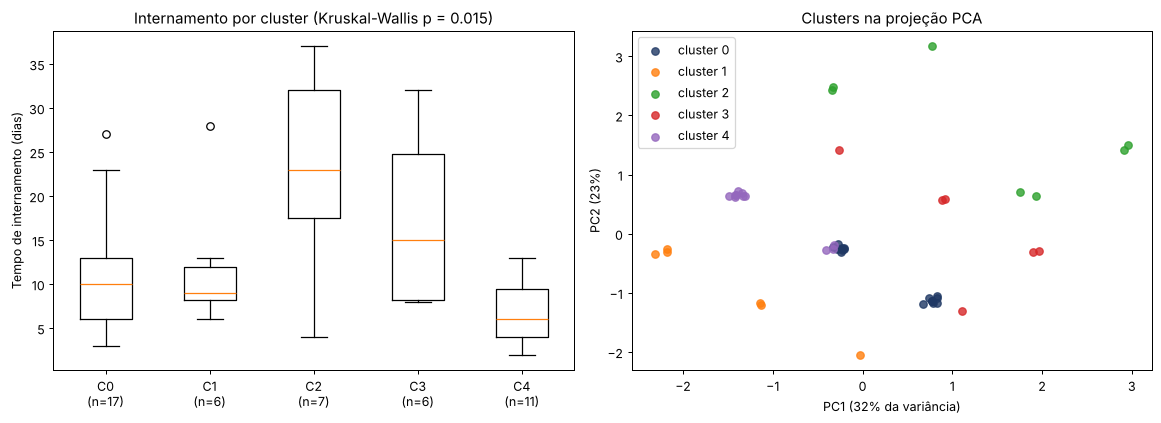

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Internamento por cluster (validação externa)
dados = [los[d.cluster == c] for c in range(K_FINAL)]
axes[0].boxplot(dados)
axes[0].set_xticks(range(1, K_FINAL + 1), [f"C{c}\n(n={len(x)})" for c, x in enumerate(dados)])
p = kruskal(*dados).pvalue
axes[0].set(ylabel="Tempo de internamento (dias)", title=f"Internamento por cluster (Kruskal-Wallis p = {p:.3f})")

# Projeção nas 2 primeiras componentes principais, com um pequeno desvio para separar pontos sobrepostos
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z) + np.random.default_rng(SEED).normal(0, 0.06, (len(Z), 2))
for c in range(K_FINAL):
    axes[1].scatter(P[d.cluster == c, 0], P[d.cluster == c, 1], color=CORES[c], label=f"cluster {c}", alpha=0.8)
v = pca.explained_variance_ratio_ * 100
axes[1].set(xlabel=f"PC1 ({v[0]:.0f}% da variância)", ylabel=f"PC2 ({v[1]:.0f}%)", title="Clusters na projeção PCA")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "figura_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

### Comparação: e se usarmos também os sinais vitais?

A Tabela 7 do relatório fala em agrupar pelos sinais vitais **e** pelas patologias. Testamos essa versão com as 25 variáveis originais do `dataset_clustering.csv` (19 de sinais vitais, 5 frações de patologia e o número de patologias distintas). O objetivo é justificar no relatório por que ficámos só com as patologias.

In [11]:
Z_todas = StandardScaler().fit_transform(d[SINAIS + FRAC + ["n_patologias_distintas"]])
linhas_todas = [avaliar(Z_todas, "K-means (todas as variáveis)", ALGORITMOS["K-means"], k)[1] for k in K_CANDIDATOS]
display(pd.DataFrame(linhas_todas).round(3))

,algoritmo,k,silhouette,davies_bouldin,calinski_harabasz,menor_cluster,kruskal_p,ARI_bootstrap
0,K-means (todas as variáveis),2,0.116,2.381,7.326,23,0.070,0.369
1,K-means (todas as variáveis),3,0.114,1.924,7.412,15,0.023,0.537
2,K-means (todas as variáveis),4,0.127,1.760,6.598,3,0.005,0.502
3,K-means (todas as variáveis),5,0.129,1.678,6.398,4,0.001,0.474


Com as 25 variáveis, a *silhouette* fica em cerca de 0,1 e o ARI bem abaixo de 0,6. Os bebés não formam grupos claros e as partições mudam de amostra para amostra. Os sinais vitais têm muita variação individual e diluem a estrutura das patologias. Por isso, o modelo final usa só as condições clínicas, e os sinais vitais servem para descrever os perfis.

## 6.1 Avaliar os resultados face aos critérios de sucesso (Tabela 8)

In [12]:
r = comparacao.query("algoritmo == @ALG_FINAL and k == @K_FINAL").iloc[0]
criterios = pd.DataFrame([
    ("Silhouette média > 0,25", f"{r.silhouette:.3f}", r.silhouette > 0.25),
    ("Todos os clusters com pelo menos 3 bebés", f"menor = {r.menor_cluster}", r.menor_cluster >= 3),
    ("Internamento difere entre clusters (Kruskal-Wallis p < 0,05)", f"p = {r.kruskal_p:.3f}", r.kruskal_p < 0.05),
    ("Estabilidade: ARI médio em bootstrap >= 0,6", f"{r.ARI_bootstrap:.3f}", r.ARI_bootstrap >= 0.6),
], columns=["critério", "valor obtido", "cumprido"])
criterios["cumprido"] = criterios["cumprido"].map({True: "✔", False: "✘"})
criterios

,critério,valor obtido,cumprido
0,"Silhouette média > 0,25",0.463,✔
1,Todos os clusters com pelo menos 3 bebés,menor = 6,✔
2,"Internamento difere entre clusters (Kruskal-Wallis p < 0,05)",p = 0.015,✔
3,"Estabilidade: ARI médio em bootstrap >= 0,6",0.734,✔


**Leitura dos resultados (para o capítulo 6):**

- A solução final cumpre os quatro critérios técnicos da Tabela 8.
- Com 47 bebés e 5 variáveis binárias, os clusters correspondem, na prática, a **combinações típicas de patologias**. É uma vantagem para o negócio (O3), porque cada perfil se explica numa frase, mas deve ser dito no relatório.
- A diferença no internamento entre clusters é a ligação ao objetivo de negócio: perfis com mais patologias pedem mais dias de cama e mais vigilância.
- **Limitações:** poucos bebés por cluster (três clusters têm só 6 ou 7), e 11 internamentos estão cortados no fim da recolha.

## Guardar o modelo final (para o Projeto 2)

Guardamos o *pipeline* (normalização + K-means) e a lista de variáveis, para o BI atribuir um cluster a um bebé novo, e a tabela bebé → cluster para os *dashboards*.

In [13]:
modelo_final = make_pipeline(StandardScaler(), KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED)).fit(X)
assert adjusted_rand_score(modelo_final.predict(X), d["cluster"]) == 1, "o pipeline final não reproduz os clusters"
joblib.dump({"modelo": modelo_final, "variaveis": TEM,
             "nota": "tem_pat_<grupo> = 1 se o bebé teve esse grupo de patologias em algum dia"},
            MODEL_DIR / "modelo_clustering.joblib")
d[["episodio", "cluster"] + TEM + ["n_patologias_distintas", "los_validacao", "cens_direita"]].to_csv(
    PROC_DIR / "clusters_bebes.csv", index=False)
print("Guardado:", MODEL_DIR / "modelo_clustering.joblib")
print("Guardado:", PROC_DIR / "clusters_bebes.csv")

Guardado: /home/claude/proj/models/modelo_clustering.joblib
Guardado: /home/claude/proj/data/processed/clusters_bebes.csv
